In [1]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

In [2]:
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32') 
query = np.array([[0.5, 0.5]], dtype='float32') 

In [3]:
index_flat = faiss.IndexFlatL2(2)
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)
end = time.time()
time_flat = end - start

In [4]:
nlist = 10   
m = 2        
quantizer = faiss.IndexFlatL2(2)
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)

index_ivfpq.train(X) 
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points


In [5]:
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)

Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Waktu Exact: 0.01171565055847168
Waktu IVF+PQ: 0.018794536590576172


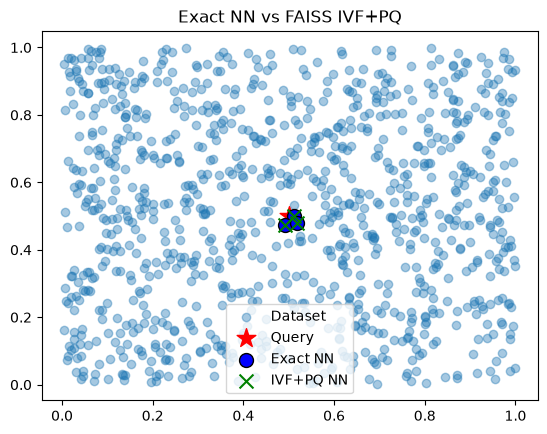

In [6]:
plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Dataset")
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")

plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")

plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Exact NN vs FAISS IVF+PQ")
plt.show()